In [1]:
import numpy as np
import emcee
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "figure.figsize": (6, 4)})
np.random.seed(11)

def run_mcmc(log_post, start, n_walkers=16, n_burn=1500, n_steps=5000):
    # small reusable emcee wrapper -> flat samples
    n_dim = len(start); p0 = start + 0.03*np.random.randn(n_walkers, n_dim)
    s = emcee.EnsembleSampler(n_walkers, n_dim, log_post)
    st = s.run_mcmc(p0, n_burn, progress=False); s.reset(); s.run_mcmc(st, n_steps, progress=False)
    try: tau_ac = float(np.mean(s.get_autocorr_time(quiet=True)))
    except Exception: tau_ac = float("nan")
    ess = (n_walkers*n_steps/tau_ac) if tau_ac == tau_ac else float("nan")
    print("   acceptance=%.2f | autocorr ~%.0f steps | ~%.0f independent samples" % (s.acceptance_fraction.mean(), tau_ac, ess))
    return s.get_chain(flat=True)
print("emcee", emcee.__version__, "| numpy", np.__version__)

emcee 3.1.6 | numpy 2.4.6


In [2]:
# TRUE scaling-relation parameters (our ground truth), near the Murata et al. 2018 values:
# NOTE: `sigma_true` is the INTRINSIC scatter sigma_{ln lambda | M} (a property of nature, ~0.25-0.46
# in Murata 2018) -- NOT a richness MEASUREMENT error. Real lambda also has measurement uncertainty
# ~0.05-0.1 dex (small compared to the intrinsic scatter and ignored here for clarity).
A_true, B_true, sigma_true = 3.20, 1.00, 0.35      # normalization, mass slope, intrinsic scatter (lognormal)
print("TRUE hyper-parameters:  A=%.2f  B=%.2f  sigma_intr=%.2f" % (A_true, B_true, sigma_true))

TRUE hyper-parameters:  A=3.20  B=1.00  sigma_intr=0.35


drew 125 clusters in 3 richness bins: {'20-30': 60, '30-45': 40, '45-65': 25}


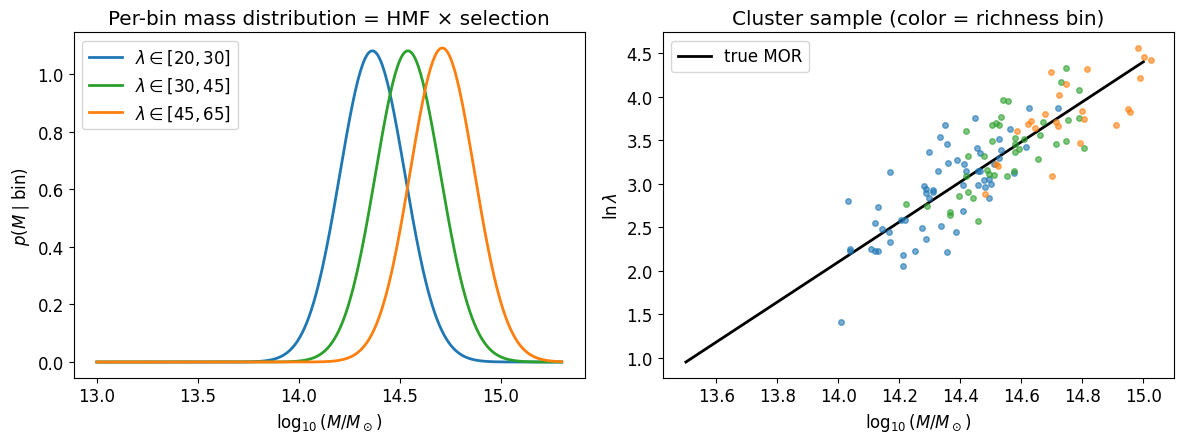

In [5]:
# --- Step 1: define richness bins (similar to DES Y1 redMaPPer) ---
bins = [(20, 30), (30, 45), (45, 65)]
n_per_bin = [60, 40, 25]                                  # cluster counts per bin (steeply falling)

# --- Step 2: posterior on M inside one bin: p(M | bin) ∝ dn/dM × P(lambda in bin | M) ---
alpha_mf = 1.9                                            # dn/dM ∝ M^-alpha (rough Tinker slope at cluster scales)
from math import erf
def mass_pdf_in_bin(lam_lo, lam_hi, n_grid=400):
    lnM = np.linspace(np.log(1e13), np.log(2e15), n_grid)
    mean_lnl = A_true + B_true*(lnM - np.log(3e14))                          # <ln lambda | M> on grid
    z_hi = (np.log(lam_hi) - mean_lnl) / (sigma_true*np.sqrt(2))
    z_lo = (np.log(lam_lo) - mean_lnl) / (sigma_true*np.sqrt(2))
    P_in_bin = 0.5*(np.vectorize(erf)(z_hi) - np.vectorize(erf)(z_lo))       # P(lambda in bin | M)
    pdf = P_in_bin * np.exp(-alpha_mf*(lnM - np.log(3e14)))                   # × mass function (M^-alpha factor; M dM absorbed)
    return lnM, pdf/np.trapezoid(pdf, lnM)

# --- Step 3: draw each cluster: mass from the bin's p(M|bin), then concentration from the M-c relation ---
sigma_mc = 0.15                                           # scatter in concentration at fixed mass (Murata-ish)
M_pop, c_pop, bin_idx, lam_pop = [], [], [], []
for b, (lam_lo, lam_hi) in enumerate(bins):
    lnM, pdf = mass_pdf_in_bin(lam_lo, lam_hi)
    lnM_j = np.random.choice(lnM, size=n_per_bin[b], p=pdf/pdf.sum())        # mass draws
    c_mean = 5.0 - 0.3*(lnM_j - np.log(3e14))                                 # c(M) ~ Diemer18-ish trend
    c_j    = c_mean + sigma_mc*np.random.randn(n_per_bin[b])
    # the cluster's own richness (draws ln lambda from the MOR, then takes exp)
    lam_j = np.exp(A_true + B_true*(lnM_j - np.log(3e14)) + sigma_true*np.random.randn(n_per_bin[b]))
    M_pop.append(np.exp(lnM_j)); c_pop.append(c_j); lam_pop.append(lam_j); bin_idx.append(np.full(n_per_bin[b], b))
M_true   = np.concatenate(M_pop);   c_true   = np.concatenate(c_pop)
lam_true = np.concatenate(lam_pop); bin_idx  = np.concatenate(bin_idx)
n_clusters = len(M_true)
print("drew", n_clusters, "clusters in", len(bins), "richness bins:", dict(zip([f"{l[0]}-{l[1]}" for l in bins], n_per_bin)))

# show the per-bin mass distribution (the Eddington-bias-relevant object)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
colors = ["tab:blue", "tab:green", "tab:orange"]
for b, (lam_lo, lam_hi) in enumerate(bins):
    lnM, pdf = mass_pdf_in_bin(lam_lo, lam_hi)
    ax[0].plot(lnM/np.log(10), pdf, color=colors[b], lw=2, label=fr"$\lambda\in[{lam_lo},{lam_hi}]$")
    sel = bin_idx == b
    ax[1].errorbar(np.log10(M_true[sel]), np.log(lam_true[sel]), fmt="o", ms=4, color=colors[b], alpha=0.6)
ax[0].set_xlabel(r"$\log_{10}(M/M_\odot)$"); ax[0].set_ylabel(r"$p(M\mid\mathrm{bin})$"); ax[0].set_title("Per-bin mass distribution = HMF × selection"); ax[0].legend()
gridM = np.linspace(13.5, 15.0, 50); ax[1].plot(gridM, A_true + B_true*(gridM*np.log(10)-np.log(3e14)), "k-", lw=2, label="true MOR")
ax[1].set_xlabel(r"$\log_{10}(M/M_\odot)$"); ax[1].set_ylabel(r"$\ln\lambda$"); ax[1].set_title("Cluster sample (color = richness bin)"); ax[1].legend()
plt.tight_layout(); plt.show()

wl_samples shape = (125, 3000)  (clusters x posterior samples)
(in a real pipeline these come from each cluster's WL fit -- here Gaussian for clarity)


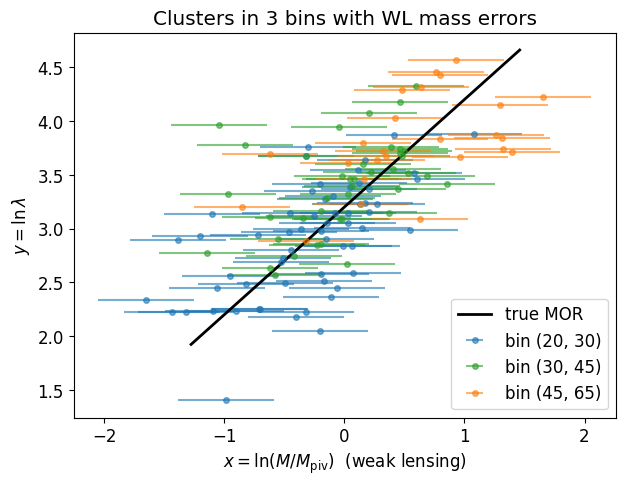

In [6]:
sigma_WL = 0.40                                        # 1-sigma WL uncertainty on x = ln(M/Mpiv)
x_true = np.log(M_true / 3e14)                          # the per-cluster latent (Tutorial 1's "a")
y_obs  = np.log(lam_true)                               # the per-cluster richness
x_wl   = x_true + sigma_WL*np.random.randn(n_clusters)  # noisy WL mass point estimate

n_samples = 3000
wl_samples = x_wl[:, None] + sigma_WL*np.random.randn(n_clusters, n_samples)
print("wl_samples shape =", wl_samples.shape, " (clusters x posterior samples)")
print("(in a real pipeline these come from each cluster's WL fit -- here Gaussian for clarity)")

grid = np.linspace(x_true.min()-0.2, x_true.max()+0.2, 50)
plt.figure(figsize=(7, 5))
for b in range(len(bins)):
    sel = bin_idx == b
    plt.errorbar(x_wl[sel], y_obs[sel], xerr=sigma_WL, fmt="o", ms=4, alpha=0.6, color=colors[b], label=f"bin {bins[b]}")
plt.plot(grid, A_true + B_true*grid, "k-", lw=2, label="true MOR")
plt.xlabel(r"$x=\ln(M/M_{\rm piv})$  (weak lensing)"); plt.ylabel(r"$y=\ln\lambda$"); plt.title("Clusters in 3 bins with WL mass errors"); plt.legend(); plt.show()

Attempt 1 (naive OLS):  A=3.26  B=0.62  sigma=0.434
expected attenuated slope = B*0.63 = 0.63   (true B=1.00)


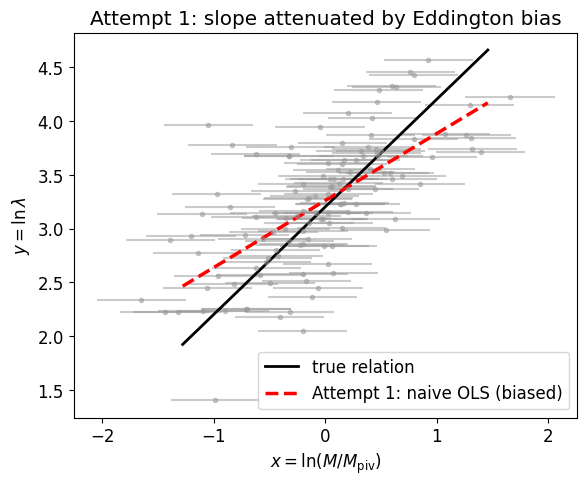

In [7]:
B_naive, A_naive = np.polyfit(x_wl, y_obs, 1)
sigma_naive = (y_obs - (A_naive + B_naive*x_wl)).std()
sigma_mass_eff = x_true.std()                            # the *realized* spread of true log-masses in this sample
attn = sigma_mass_eff**2 / (sigma_mass_eff**2 + sigma_WL**2)
print("Attempt 1 (naive OLS):  A=%.2f  B=%.2f  sigma=%.3f" % (A_naive, B_naive, sigma_naive))
print("expected attenuated slope = B*%.2f = %.2f   (true B=%.2f)" % (attn, B_true*attn, B_true))
sigma_mass = sigma_mass_eff                              # what later cells call sigma_mass

plt.figure(figsize=(6.5, 5))
plt.errorbar(x_wl, y_obs, xerr=sigma_WL, fmt="o", ms=3, color="0.6", alpha=0.5)
plt.plot(grid, A_true + B_true*grid, "k-", lw=2, label="true relation")
plt.plot(grid, A_naive + B_naive*grid, "r--", lw=2.5, label="Attempt 1: naive OLS (biased)")
plt.xlabel(r"$x=\ln(M/M_{\rm piv})$"); plt.ylabel(r"$y=\ln\lambda$")
plt.title("Attempt 1: slope attenuated by Eddington bias"); plt.legend(); plt.show()

   acceptance=0.65 | autocorr ~38 steps | ~2103 independent samples
Attempt 2 (recycle, FLAT prior):  A=3.26  B=0.63  sigma=0.361   <- same biased slope as Attempt 1


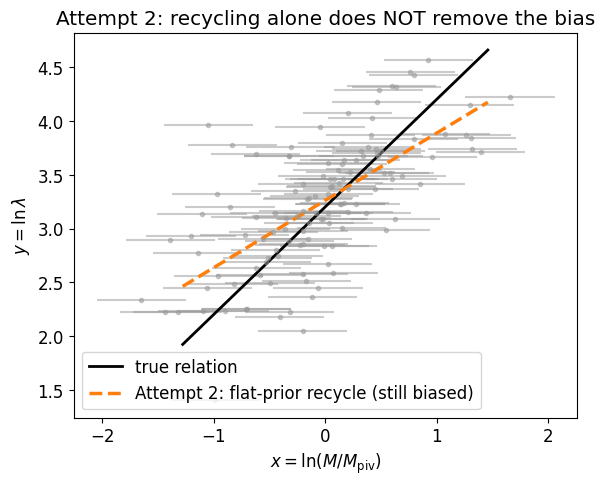

In [8]:
def hyper_logpost_flat(params):
    A, B, log_s = params; s = np.exp(log_s)
    if s > 3: return -np.inf
    tot = 0.0
    for j in range(n_clusters):
        like = np.exp(-0.5*((y_obs[j] - (A + B*wl_samples[j]))/s)**2) / s     # p(richness | mass sample)
        tot += np.log(like.mean() + 1e-300)
    return tot + log_s    # +log_s = Jacobian for sampling in log(sigma)  (=> flat prior on sigma)
chain_flat = run_mcmc(hyper_logpost_flat, start=np.array([A_true, B_true, np.log(sigma_true)]))
A_f, B_f, s_f = chain_flat[:, 0], chain_flat[:, 1], np.exp(chain_flat[:, 2])
print("Attempt 2 (recycle, FLAT prior):  A=%.2f  B=%.2f  sigma=%.3f   <- same biased slope as Attempt 1" % (A_f.mean(), B_f.mean(), s_f.mean()))

plt.figure(figsize=(6.5, 5))
plt.errorbar(x_wl, y_obs, xerr=sigma_WL, fmt="o", ms=3, color="0.6", alpha=0.5)
plt.plot(grid, A_true + B_true*grid, "k-", lw=2, label="true relation")
plt.plot(grid, A_f.mean() + B_f.mean()*grid, "--", color="tab:orange", lw=2.5, label="Attempt 2: flat-prior recycle (still biased)")
plt.xlabel(r"$x=\ln(M/M_{\rm piv})$"); plt.ylabel(r"$y=\ln\lambda$")
plt.title("Attempt 2: recycling alone does NOT remove the bias"); plt.legend(); plt.show()

   acceptance=0.64 | autocorr ~40 steps | ~2012 independent samples
Attempt 3 (recycle + mass function):  A=3.26±0.04  B=1.01±0.10  sigma=0.298±0.057
                                       -> recovers truth (A=3.20, B=1.00, sigma=0.35)


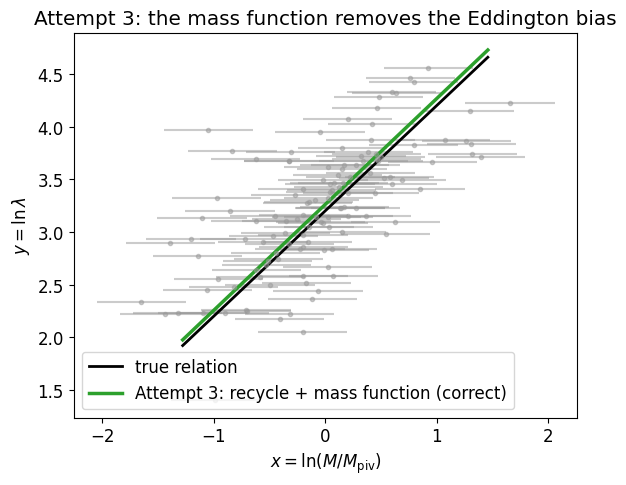

In [9]:
def hyper_logpost_massfunc(params):
    A, B, log_s = params; s = np.exp(log_s)
    if s > 3: return -np.inf
    tot = 0.0
    for j in range(n_clusters):
        like   = np.exp(-0.5*((y_obs[j] - (A + B*wl_samples[j]))/s)**2) / s
        massfn = np.exp(-0.5*(wl_samples[j]/sigma_mass)**2)        # p(x) = halo mass function (the weight)
        tot += np.log((like*massfn).mean() + 1e-300)
    return tot + log_s    # +log_s = Jacobian for sampling in log(sigma)  (=> flat prior on sigma)
chain_mf = run_mcmc(hyper_logpost_massfunc, start=np.array([A_true, B_true, np.log(sigma_true)]))
A_m, B_m, s_m = chain_mf[:, 0], chain_mf[:, 1], np.exp(chain_mf[:, 2])
print("Attempt 3 (recycle + mass function):  A=%.2f±%.2f  B=%.2f±%.2f  sigma=%.3f±%.3f"
      % (A_m.mean(), A_m.std(), B_m.mean(), B_m.std(), s_m.mean(), s_m.std()))
print("                                       -> recovers truth (A=%.2f, B=%.2f, sigma=%.2f)" % (A_true, B_true, sigma_true))

plt.figure(figsize=(6.5, 5))
plt.errorbar(x_wl, y_obs, xerr=sigma_WL, fmt="o", ms=3, color="0.6", alpha=0.5)
plt.plot(grid, A_true + B_true*grid, "k-", lw=2, label="true relation")
plt.plot(grid, A_m.mean() + B_m.mean()*grid, "-", color="tab:green", lw=2.5, label="Attempt 3: recycle + mass function (correct)")
plt.xlabel(r"$x=\ln(M/M_{\rm piv})$"); plt.ylabel(r"$y=\ln\lambda$")
plt.title("Attempt 3: the mass function removes the Eddington bias"); plt.legend(); plt.show()

                              A       B       sigma_intr
truth                    :  3.20    1.00    0.350
Attempt 1 naive OLS      :  3.26    0.62    0.434   <- Eddington bias
Attempt 2 flat-recycle   :  3.26    0.63    0.361   <- still biased
Attempt 3 + mass function:  3.26    1.01    0.298   <- correct


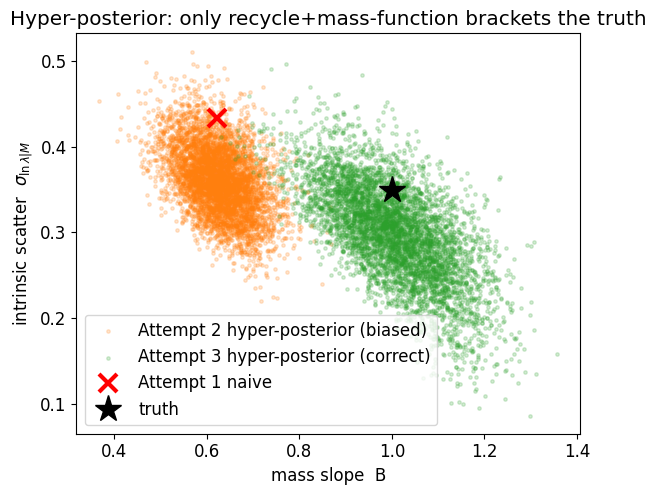

In [10]:
print("                              A       B       sigma_intr")
print("truth                    :  %.2f    %.2f    %.3f" % (A_true, B_true, sigma_true))
print("Attempt 1 naive OLS      :  %.2f    %.2f    %.3f   <- Eddington bias" % (A_naive, B_naive, sigma_naive))
print("Attempt 2 flat-recycle   :  %.2f    %.2f    %.3f   <- still biased" % (A_f.mean(), B_f.mean(), s_f.mean()))
print("Attempt 3 + mass function:  %.2f    %.2f    %.3f   <- correct" % (A_m.mean(), B_m.mean(), s_m.mean()))

# the hyper-posterior on (slope B, intrinsic scatter sigma): truth inside the correct one, not the biased one
plt.figure(figsize=(6.5, 5.2))
plt.scatter(B_f[::15], s_f[::15], s=6, alpha=0.2, color="tab:orange", label="Attempt 2 hyper-posterior (biased)")
plt.scatter(B_m[::15], s_m[::15], s=6, alpha=0.2, color="tab:green", label="Attempt 3 hyper-posterior (correct)")
plt.plot(B_naive, sigma_naive, "rx", ms=13, mew=3, label="Attempt 1 naive")
plt.plot(B_true, sigma_true, "k*", ms=20, label="truth")
plt.xlabel("mass slope  B"); plt.ylabel(r"intrinsic scatter  $\sigma_{\ln\lambda|M}$")
plt.title("Hyper-posterior: only recycle+mass-function brackets the truth"); plt.legend(); plt.show()

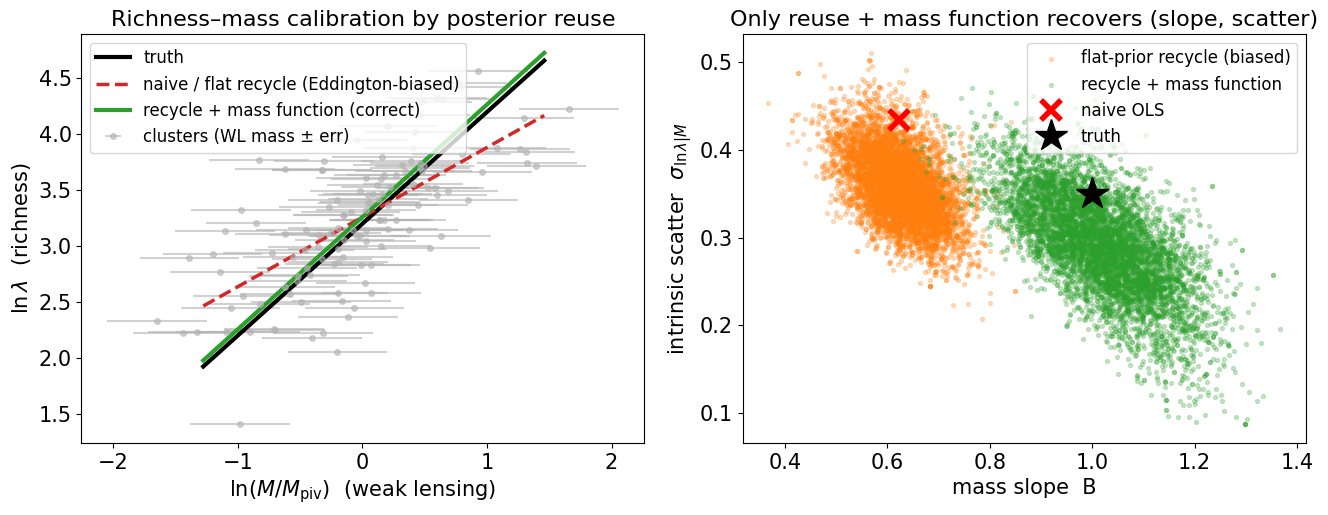

saved -> slide_figures/richness_mass_calibration.png


In [11]:
# --- polished figure for a PROJECT-PITCH SLIDE (saved high-res to slide_figures/) ---
import os; os.makedirs("slide_figures", exist_ok=True)
with plt.rc_context({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "legend.fontsize": 12,
                     "savefig.dpi": 220, "savefig.bbox": "tight"}):
    fig, ax = plt.subplots(1, 2, figsize=(13.5, 5.4))
    # LEFT: the relation -- data + true + biased + correct
    ax[0].errorbar(x_wl, y_obs, xerr=sigma_WL, fmt="o", ms=4, color="0.7", alpha=0.6, label="clusters (WL mass ± err)")
    ax[0].plot(grid, A_true + B_true*grid, "k-", lw=3, label="truth")
    ax[0].plot(grid, A_naive + B_naive*grid, "--", color="tab:red", lw=2.5, label="naive / flat recycle (Eddington-biased)")
    ax[0].plot(grid, A_m.mean() + B_m.mean()*grid, "-", color="tab:green", lw=3, label="recycle + mass function (correct)")
    ax[0].set_xlabel(r"$\ln(M/M_{\rm piv})$  (weak lensing)"); ax[0].set_ylabel(r"$\ln\lambda$  (richness)")
    ax[0].set_title("Richness–mass calibration by posterior reuse"); ax[0].legend(loc="upper left")
    # RIGHT: the (slope, scatter) hyper-posterior
    ax[1].scatter(B_f[::12], s_f[::12], s=8, alpha=0.25, color="tab:orange", label="flat-prior recycle (biased)")
    ax[1].scatter(B_m[::12], s_m[::12], s=8, alpha=0.25, color="tab:green", label="recycle + mass function")
    ax[1].plot(B_naive, sigma_naive, "rx", ms=15, mew=4, label="naive OLS")
    ax[1].plot(B_true, sigma_true, "k*", ms=24, label="truth")
    ax[1].set_xlabel("mass slope  B"); ax[1].set_ylabel(r"intrinsic scatter  $\sigma_{\ln\lambda|M}$")
    ax[1].set_title("Only reuse + mass function recovers (slope, scatter)"); ax[1].legend(loc="upper right")
    fig.tight_layout(); fig.savefig("slide_figures/richness_mass_calibration.png"); plt.show()
print("saved -> slide_figures/richness_mass_calibration.png")